In [47]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys
from SiEPIC.utils import klive

# Generic Imports
import os
import pya
from pya import *
import numpy as np
import pandas as pd
from SiEPIC.utils import klive
from SiEPIC.scripts import connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC._globals import Python_Env
from SiEPIC.utils.layout import new_layout
import sys
import openpyxl


if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "Shallow_Etch_BTO_PDK","klayout"))

    # Now try importing the PDK
    import Shallow_Etch_BTO



In [48]:
tech_name = 'Shallow_Etch_BTO'  
gclib_name = 'Shallow_Etch_BTO'
lib_name = 'Shallow_Etch_BTO'

# top_cell_name = 'Test'  # Change this to the name of the top cell from the floorplan

chip_name = 'SiEPICfab_bto'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_bto'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
# layout_file = os.path.join("designs", f"{top_cell_name}.oas")  # Name of the soon-to-be chip

def GDS_Export(topcell,cellname):
    # Export for fabrication, removing PCells
    path = os.path.join(f"gds_in")
    #r"D:\Github\SiEPIC-Klayout-in-VSCode\floorplan_btomrr\gds_in"

    file_out = export_layout(topcell, path, cellname, relative_path = '', format='gds', screenshot=True)

    # Display the layout in KLayout, using KLayout Package "klive", which needs to be installed in the KLayout Application
    if Python_Env == 'Script':
        klive.show(file_out, technology=tech_name)

    print('\n COMPLETED \n')


In [49]:
cell1_name = 'cell_gc'  # Change this to the name of the top cell from the floorplan

chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{cell1_name}.oas")  # Name of the soon-to-be chip


Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmp434m8636\\cell_gc.gds"}
Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmp434m8636\\cell_gc.gds"}


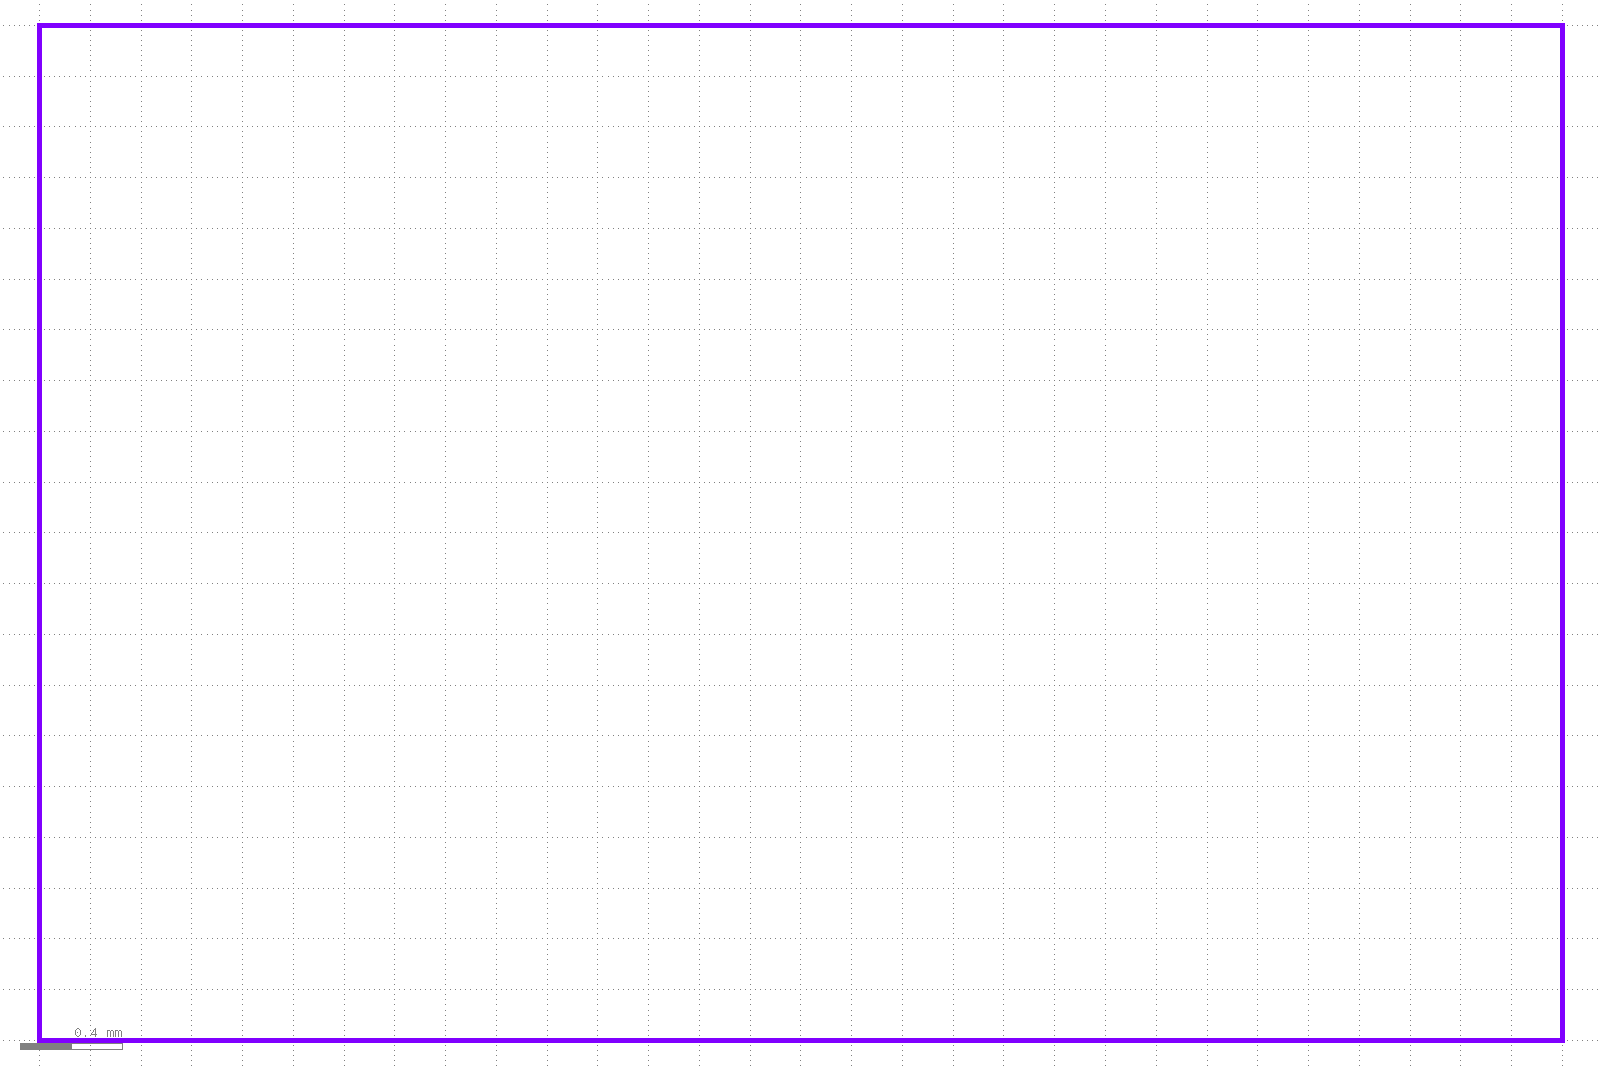

In [50]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(cell1_name)
_top_cell.write(layout_file) #save the layout to a GDS file

"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(cell1_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [61]:
# ============================================================
# GC settings profiles
# Define once and reuse in later cells
# ============================================================
GC_SETTINGS_STANDARD = {
    "gc_cell_name": "BTO_ShEtch_GC_1550",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 2,
}

GC_SETTINGS_UNIVERSAL = {
    "gc_cell_name": "BTO_Universal_GC",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 2,
    "label_location": 2,
    "parameters": {
        "target_length": 25,
        "duty_cycle": 0.45,
        "pitch": 1.045,
        "radius": 25,
        "y_span": 15,
        "L_extra": 5,
        "wg_width": 1.0,
    }
}

# Preferred names for function input
GC_SETTING_FIXED = GC_SETTINGS_STANDARD
GC_SETTING_DEFINE = GC_SETTINGS_UNIVERSAL

WG_SETTINGS = {
    "wg_type": "Low-loss Bend Waveguide, w=1.0um r=50um",
}
device_prefix = "opt_in_TE_1550_device_XX"

# margin_x = 250

In [59]:
def place_gc_loopback(
    ParentCell=None,
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="gc_loopback",
    device_label="opt_in_TE_1550_device_JSong_Loopback",
    xmax=None,
    num_gc=None,
    port_pairs=[(0, 1)],
    x_spacing=20.0,
    row_spacing=None,
    turtle_A=None,
    gc_setting=None,
    tech_name_input=None,
    layout=None,
):
    """
    Place a GC array and connect selected GC pairs with loopback waveguides.

    Expected gc_setting input:
    - GC_SETTING_FIXED
    - GC_SETTING_DEFINE
    or a copied/modified dict (e.g., pitch sweep based on GC_SETTING_DEFINE).
    """

    parent_cell = top_cell if ParentCell is None else ParentCell
    if parent_cell is None:
        raise ValueError("ParentCell is required when top_cell is not available")

    ly_local = layout if layout is not None else parent_cell.layout()
    if ly_local is None:
        raise ValueError("Could not resolve layout. Pass layout=ly explicitly.")

    if gc_setting is None:
        gc_setting = GC_SETTING_FIXED

    if not isinstance(gc_setting, dict):
        raise TypeError("gc_setting must be a dict (e.g., GC_SETTING_FIXED or GC_SETTING_DEFINE)")

    # Copy to protect global dictionaries when sweeping parameters.
    active_gc_settings = dict(gc_setting)
    active_gc_settings["parameters"] = dict(active_gc_settings.get("parameters", {}))

    # Use global WG_SETTINGS as requested.
    wg_type = WG_SETTINGS.get("wg_type", "")

    # tech_name from input first; fallback to gc settings then global.
    tech_local = tech_name_input if tech_name_input is not None else globals().get("tech_name", None)
    tech_local = active_gc_settings.get("tech_name", tech_local)

    gc_cell_name = active_gc_settings["gc_cell_name"]
    gc_library = active_gc_settings["gc_library"]
    gc_pitch = active_gc_settings["gc_pitch"]
    label_location = active_gc_settings["label_location"]
    gc_parameters = active_gc_settings.get("parameters", {})

    if num_gc is None:
        num_gc = active_gc_settings["default_num_gc"]

    if y_pos_GC is None:
        y_pos_GC = parent_cell.bbox().height() * dbu

    if xmax is None:
        xmax = parent_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    gc_ports = ["opt1"] * num_gc

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2")

    for pair in port_pairs:
        if len(pair) != 2:
            raise ValueError(f"Each entry in port_pairs must have 2 indices, got {pair}")
        i, j = pair
        if not (0 <= i < num_gc and 0 <= j < num_gc):
            raise ValueError(f"Invalid GC pair {pair} for num_gc={num_gc}")

    # Normalize turtle paths.
    # None or [] means auto-routing (no explicit turtle path).
    if turtle_A is None or turtle_A == []:
        turtle_list = [None for _ in port_pairs]
    elif len(port_pairs) == 1:
        turtle_list = [turtle_A]
    else:
        if isinstance(turtle_A, list) and len(turtle_A) > 0 and isinstance(turtle_A[0], list):
            if len(turtle_A) != len(port_pairs):
                raise ValueError("Number of turtle paths must match number of port pairs")
            turtle_list = turtle_A
        else:
            turtle_list = [turtle_A for _ in port_pairs]

    cell = ly_local.create_cell(cellname)
    parent_cell.insert(CellInstArray(cell.cell_index(), Trans(Trans.R0, 0, 0)))

    use_universal_gc = gc_cell_name == "BTO_Universal_GC"

    # Universal/self-defined path: create parameterized PCell from tech.
    # Fixed path: use library loader and fall back to create_cell2 for robustness.
    if use_universal_gc:
        if tech_local is None:
            raise ValueError("tech_name_input is required for UNIVERSAL GC creation")
        gc_probe = ly_local.create_cell("BTO_Universal_GC", tech_local, gc_parameters)
    else:
        gc_probe = None
        if gc_parameters:
            gc_probe = ly_local.create_cell(gc_cell_name, gc_library, gc_parameters)
        if gc_probe is None:
            gc_probe = create_cell2(ly_local, gc_cell_name, gc_library)

    if gc_probe is None:
        raise ValueError(
            f"Could not create/load GC cell '{gc_cell_name}' from library/tech '{gc_library}' with parameters {gc_parameters}"
        )

    top_boundary = parent_cell.bbox().height() * dbu
    near_left = x_pos_GC < 100
    near_right = x_pos_GC > xmax - 150
    near_top = y_pos_GC > top_boundary - 100
    near_bottom = y_pos_GC == 0

    if y_pos_GC == top_boundary or near_top:
        y_pos_GC -= (num_gc - 1) * gc_pitch + gc_probe.bbox().height() * dbu / 2
        if x_pos_GC == 0 or near_left:
            x_pos_GC = gc_probe.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - gc_probe.bbox().width() * dbu
    elif near_bottom:
        y_pos_GC += gc_probe.bbox().height() * dbu / 2
        if near_left:
            x_pos_GC = gc_probe.bbox().width() * dbu
        elif near_right:
            x_pos_GC = xmax - gc_probe.bbox().width() * dbu

    if use_universal_gc:
        inst_GCs = []
        x_i = to_itype(x_pos_GC, dbu)
        for i in range(num_gc):
            y_i = to_itype(y_pos_GC + i * gc_pitch, dbu)
            inst = cell.insert(CellInstArray(gc_probe.cell_index(), Trans(Trans.R0, x_i, y_i)))
            inst_GCs.append(inst)
        label_x = to_itype(x_pos_GC, dbu)
        label_y = to_itype(y_pos_GC + label_location * gc_pitch, dbu)
        label = pya.Text(
            f"{device_label}",
            pya.Trans(pya.Trans.R0, label_x, label_y),
        )
        cell.shapes(ly_local.layer(ly_local.TECHNOLOGY['Text'])).insert(label).text_size = 10 / ly_local.dbu
    else:
        inst_GCs = coupler_array(
            cell,
            cell_name=gc_cell_name,
            cell_library=gc_library,
            x_offset=x_pos_GC / dbu,
            y_offset=y_pos_GC / dbu,
            label=device_label,
            label_location=label_location,
            count=num_gc,
        )

    for (i, j), turtle in zip(port_pairs, turtle_list):
        connect_pins_with_waveguide(
            inst_GCs[i],
            gc_ports[i],
            inst_GCs[j],
            gc_ports[j],
            turtle_A=turtle,
            waveguide_type=wg_type,
            r=wg_bend_radius,
        )

    next_x = cell.bbox().right * dbu + x_spacing + gc_probe.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax:
        next_x = gc_probe.bbox().width() * dbu
        next_y = cell.bbox().bottom * dbu - row_spacing - cell.bbox().height() * dbu

    return next_x, next_y, xmax


def gc_loopback(*args, **kwargs):
    """Backward-compatible alias for place_gc_loopback."""
    return place_gc_loopback(*args, **kwargs)

In [53]:
# # Example: draw GC loopback array with universal GC pitch sweep (1.015 to 1.095)
# GC_SETTINGS_UNIVERSAL = {
#     "gc_cell_name": "BTO_Universal_GC",
#     "gc_library": gclib_name,
#     "gc_pitch": 127.0*2,   # microns
#     "default_num_gc": 2,
#     "label_location": 2,
#     "parameters": {
#         "target_length": 25,
#         "duty_cycle": 0.45,
#         "pitch": 1.045,
#         "radius": 25,
#         "y_span": 15,
#         "L_extra": 5,
#         "wg_width": 1.0,
#     }
# }

# x_sweep = 0
# y_sweep = top_cell.bbox().height() * dbu
# x_max = top_cell.bbox().width() * dbu

# # Route 100 um straight out from the GC before the first bend, then cross the pair spacing.
# loopback_turtle = [100, 90, 127*2, -90, 100]

# for pitch in np.round(np.arange(1.015, 1.095 + 1e-9, 0.01), 3):
#     sweep_settings = dict(GC_SETTINGS_UNIVERSAL)
#     sweep_settings["profile"] = "gc_settings_define"
#     sweep_settings["parameters"] = dict(GC_SETTINGS_UNIVERSAL["parameters"])
#     sweep_settings["parameters"]["pitch"] = float(pitch)

#     x_sweep, y_sweep, x_max = place_gc_loopback(
#         ParentCell=top_cell,
#         x_pos_GC=x_sweep,
#         y_pos_GC=y_sweep,
#         cellname=f"gc_loopback_pitch_{pitch:.3f}".replace(".", "p"),
#         device_label=f"opt_in_TE_1550_gc_loopback_pitch_{pitch:.3f}",
#         xmax=x_max,
#         num_gc=2,
#         port_pairs=[(0, 1)],
#         turtle_A=loopback_turtle,
#         gc_settings=sweep_settings,
#     )

# top_cell.show()
# top_cell.plot()

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmp434m8636\\cell_gc.gds"}


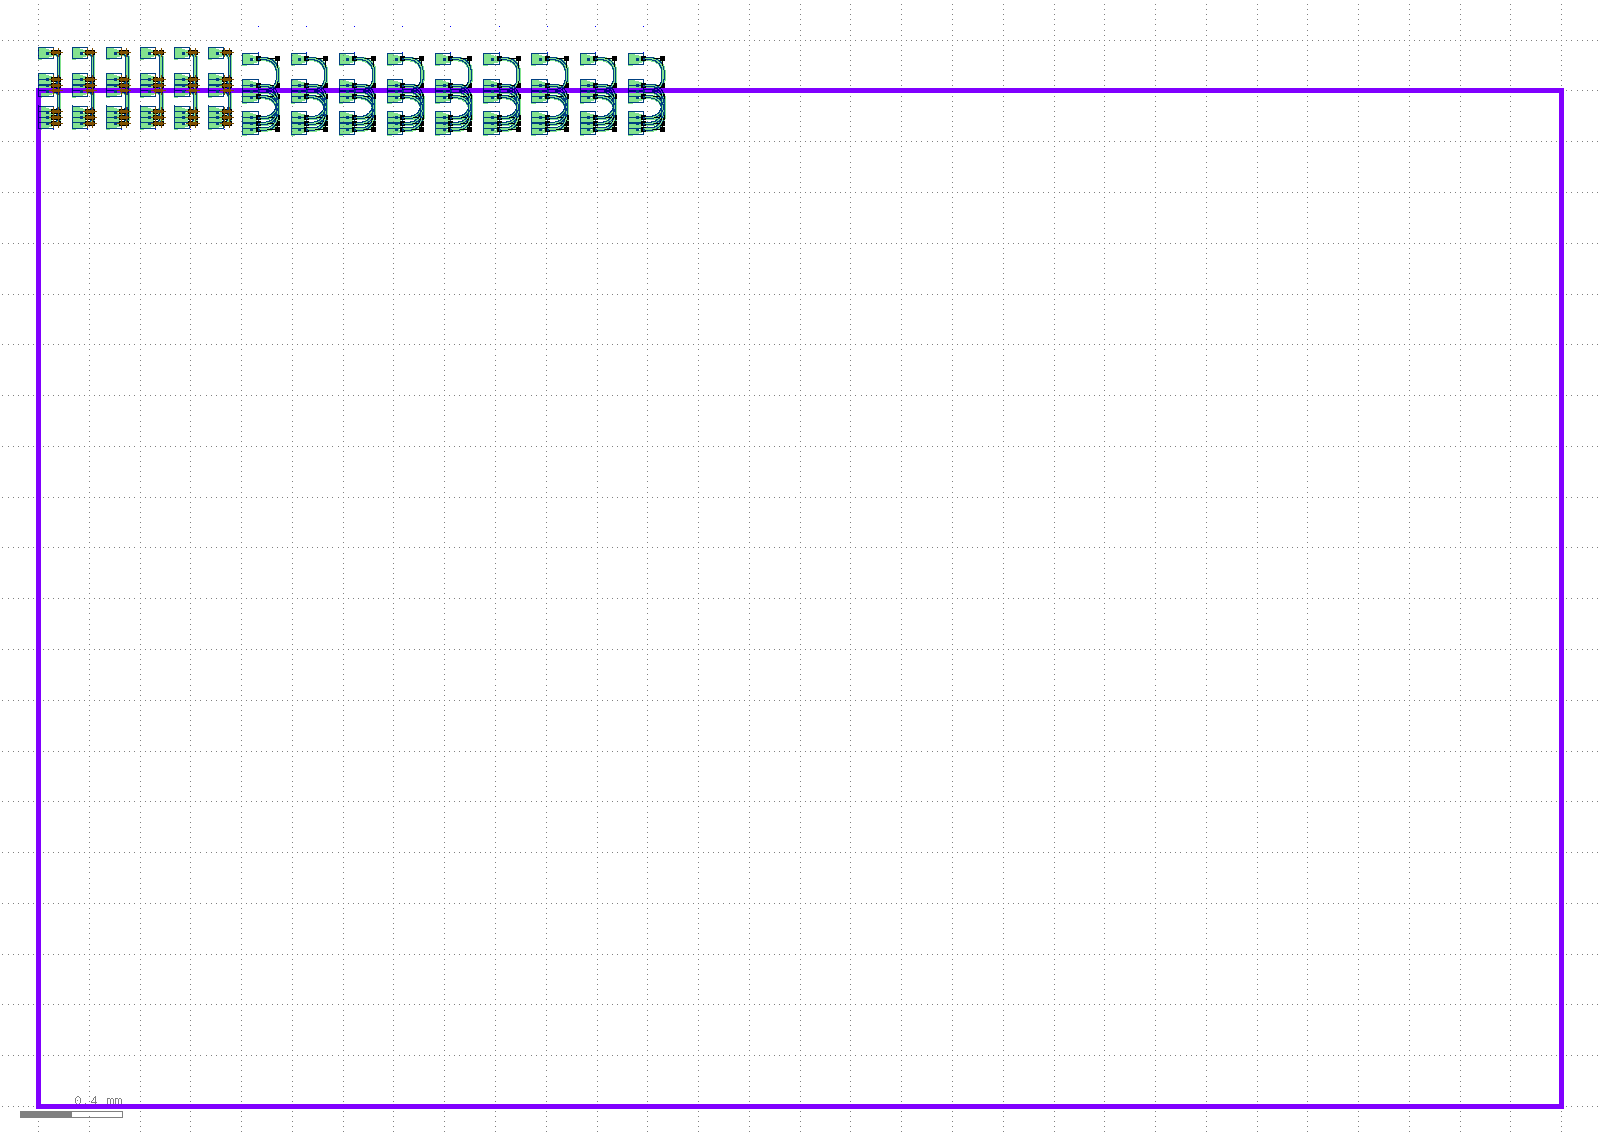

In [62]:
# Test both modes: fixed GC library cell + self-defined universal GC PCell

device_prefix = "opt_in_TE_1550_device"
device_label_area = "_GCsweep"

x_sweep = 0
y_sweep = top_cell.bbox().height() * dbu
x_max = top_cell.bbox().width() * dbu

# Custom turtle for self-defined universal GC
loopback_turtle = [75, 90, 127, -90, 75]

# ------------------------------------------------------------
# 1) Fixed grating coupler (library cell)
# Use auto-routing because pin orientation differs from universal GC.
# ------------------------------------------------------------
for i in range(6):
    devcell_name = f"fixedGC_{i}"
    label = f"{device_prefix}{device_label_area}_{devcell_name}"
    x_sweep, y_sweep, x_max = place_gc_loopback(
        ParentCell=top_cell,
        x_pos_GC=x_sweep,
        y_pos_GC=y_sweep,
        cellname=f"GC_{devcell_name}",
        device_label=label,
        xmax=x_max,
        num_gc=2,
        port_pairs=[(0, 1)],
        turtle_A=[],
        gc_setting=GC_SETTING_FIXED,
        tech_name_input=tech_name,
        layout=ly,
        x_spacing=50.0,
        row_spacing=0.0,
    )

# ------------------------------------------------------------
# 2) Self-defined universal GC (pitch sweep 1.015 -> 1.095)
# Original style: sweep_settings["parameters"]["pitch"] = ...
# ------------------------------------------------------------
for i, pitch in enumerate(np.round(np.arange(1.015, 1.095 + 1e-9, 0.01), 3)):
    sweep_settings = dict(GC_SETTING_DEFINE)
    sweep_settings["parameters"] = dict(GC_SETTING_DEFINE["parameters"])
    sweep_settings["parameters"]["pitch"] = float(pitch)

    devcell_name = f"uniGC_{i}_pitch_{pitch:.3f}".replace(".", "p")
    label = f"{device_prefix}{device_label_area}_{devcell_name}"
    x_sweep, y_sweep, x_max = place_gc_loopback(
        ParentCell=top_cell,
        x_pos_GC=x_sweep,
        y_pos_GC=y_sweep,
        cellname=f"GC_{devcell_name}",
        device_label=label,
        xmax=x_max,
        num_gc=2,
        port_pairs=[(0, 1)],
        turtle_A=loopback_turtle,
        gc_setting=sweep_settings,
        tech_name_input=tech_name,
        layout=ly,
        x_spacing=50.0,
        row_spacing=0.0,
    )

top_cell.show()
top_cell.plot()